In [ ]:
import sys

print("Python version:", sys.version)

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

if tf.config.list_physical_devices("GPU"):
    print("GPU available:", tf.config.list_physical_devices("GPU"))
else:
    print("GPU not available. CPU will be used.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow version: 2.21.0
GPU not available. CPU will be used.


In [ ]:
import os
import urllib.request
import zipfile

# Create a folder for our project dataset
os.makedirs("/content/traffic_sign_project", exist_ok=True)

# Dataset download address
url = "https://benchmark.ini.rub.de/Dataset/GTSRB_Final_Training_Images.zip"

# Save the downloaded ZIP file
zip_path = "/content/traffic_sign_project/GTSRB_Training.zip"

print("Downloading traffic sign dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Download completed!")
print("ZIP file size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

URLError: <urlopen error [Errno -2] Name or service not known>

In [ ]:
import urllib.request

url = "https://www.google.com"

try:
    response = urllib.request.urlopen(url, timeout=15)
    print("Internet connection works!")
    print("HTTP status:", response.status)
except Exception as e:
    print("Internet connection problem:", e)

Internet connection works!
HTTP status: 200


In [ ]:
!pip install -q datasets

In [ ]:
import os
import zipfile
from glob import glob

# Find ZIP files uploaded to Colab
zip_files = glob("/content/*.zip")

if not zip_files:
    print("No ZIP file found. Upload your Kaggle ZIP file to Colab first.")
else:
    zip_path = zip_files[0]
    extract_path = "/content/traffic_sign_dataset"

    os.makedirs(extract_path, exist_ok=True)

    print("ZIP file found:", os.path.basename(zip_path))
    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Extraction completed!")
    print("Dataset location:", extract_path)

    print("\nFiles and folders extracted:")
    for item in os.listdir(extract_path)[:20]:
        print(item)

No ZIP file found. Upload your Kaggle ZIP file to Colab first.


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving archive (3).zip to archive (3).zip
Uploaded files: ['archive (3).zip']


In [ ]:
import os
import zipfile

zip_path = "/content/archive (3).zip"
extract_path = "/content/traffic_sign_dataset"

os.makedirs(extract_path, exist_ok=True)

print("Extracting dataset... Please wait.")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed successfully!")

print("\nMain folders and files:")
for item in os.listdir(extract_path):
    print(item)

Extracting dataset... Please wait.
Extraction completed successfully!

Main folders and files:
Meta.csv
Test
Train
meta
train
Meta
Test.csv
Train.csv
test


In [ ]:
import os
import pandas as pd

dataset_path = "/content/traffic_sign_dataset"

print("Checking dataset structure...\n")

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")

    if level == 0:
        print()

Checking dataset structure...

traffic_sign_dataset/
  Meta.csv
  Test.csv
  Train.csv

  Test/
    12325.png
    05547.png
    09081.png
    00800.png
    04526.png
  Train/
    1/
      00001_00069_00023.png
      00001_00064_00006.png
      00001_00029_00005.png
      00001_00040_00014.png
      00001_00006_00029.png
    15/
      00015_00010_00023.png
      00015_00002_00019.png
      00015_00004_00026.png
      00015_00004_00010.png
      00015_00010_00016.png
    10/
      00010_00044_00023.png
      00010_00010_00029.png
      00010_00035_00025.png
      00010_00012_00017.png
      00010_00058_00028.png
    34/
      00034_00008_00026.png
      00034_00002_00021.png
      00034_00010_00023.png
      00034_00009_00001.png
      00034_00013_00005.png
    12/
      00012_00006_00004.png
      00012_00037_00011.png
      00012_00039_00028.png
      00012_00029_00009.png
      00012_00007_00008.png
    29/
      00029_00003_00013.png
      00029_00007_00001.png
      00029_00003_0002

Number of traffic sign classes: 43
Displaying sample traffic sign images...


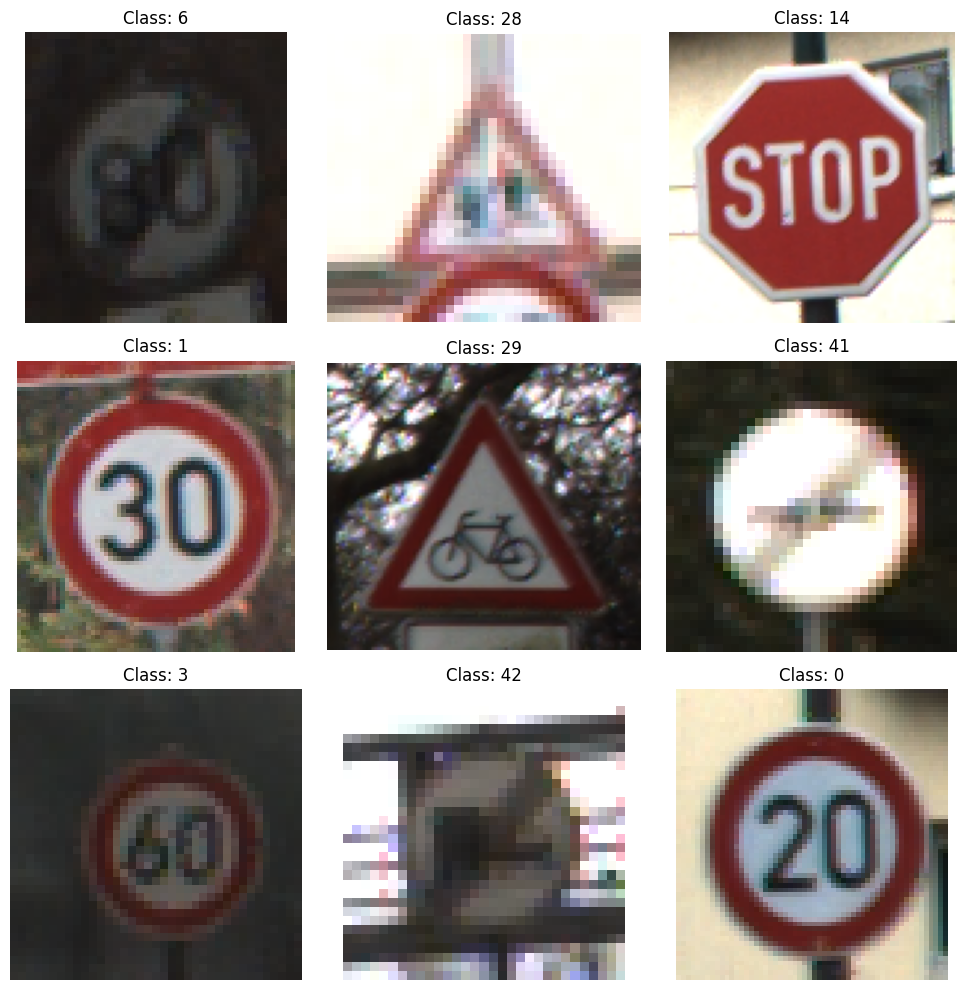

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Path to the training dataset
train_path = "/content/traffic_sign_dataset/Train"

# Find the available class folders
classes = sorted(
    [folder for folder in os.listdir(train_path)
     if os.path.isdir(os.path.join(train_path, folder))],
    key=int
)

print("Number of traffic sign classes:", len(classes))
print("Displaying sample traffic sign images...")

# Display 9 random images
plt.figure(figsize=(10, 10))

for i in range(9):
    class_id = random.choice(classes)
    class_path = os.path.join(train_path, class_id)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    image_name = random.choice(image_files)
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path).convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(f"Class: {class_id}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image

train_path = "/content/traffic_sign_dataset/Train"

# Image settings
IMG_SIZE = 30
SAMPLES_PER_CLASS = 20

X_sample = []
y_sample = []

print("Preparing a small sample of images...")

for class_id in range(43):
    class_path = os.path.join(train_path, str(class_id))

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    # Use up to 20 images from each class
    for image_name in image_files[:SAMPLES_PER_CLASS]:
        image_path = os.path.join(class_path, image_name)

        image = Image.open(image_path).convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE))

        X_sample.append(np.array(image))
        y_sample.append(class_id)

# Convert to NumPy arrays
X_sample = np.array(X_sample, dtype=np.float32) / 255.0
y_sample = np.array(y_sample, dtype=np.int64)

print("Preparation completed!")
print("Image array shape:", X_sample.shape)
print("Label array shape:", y_sample.shape)
print("Minimum pixel value:", X_sample.min())
print("Maximum pixel value:", X_sample.max())

Preparing a small sample of images...
Preparation completed!
Image array shape: (860, 30, 30, 3)
Label array shape: (860,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

train_path = "/content/traffic_sign_dataset/Train"

IMG_SIZE = 30

X = []
y = []

print("Loading all training images...")

for class_id in range(43):
    class_path = os.path.join(train_path, str(class_id))

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        try:
            image = Image.open(image_path).convert("RGB")
            image = image.resize((IMG_SIZE, IMG_SIZE))

            X.append(np.array(image))
            y.append(class_id)

        except Exception as e:
            print("Skipping unreadable image:", image_path)

    print(f"Class {class_id} loaded")

# Convert images and labels into NumPy arrays
X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y, dtype=np.int64)

print("\nFull dataset loaded!")
print("Total images:", len(X))
print("Image shape:", X.shape)
print("Labels shape:", y.shape)

# Split into training and validation datasets
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nDataset split completed!")
print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Loading all training images...
Class 0 loaded
Class 1 loaded
Class 2 loaded
Class 3 loaded
Class 4 loaded
Class 5 loaded
Class 6 loaded
Class 7 loaded
Class 8 loaded
Class 9 loaded
Class 10 loaded
Class 11 loaded
Class 12 loaded
Class 13 loaded
Class 14 loaded
Class 15 loaded
Class 16 loaded
Class 17 loaded
Class 18 loaded
Class 19 loaded
Class 20 loaded
Class 21 loaded
Class 22 loaded
Class 23 loaded
Class 24 loaded
Class 25 loaded
Class 26 loaded
Class 27 loaded
Class 28 loaded
Class 29 loaded
Class 30 loaded
Class 31 loaded
Class 32 loaded
Class 33 loaded
Class 34 loaded
Class 35 loaded
Class 36 loaded
Class 37 loaded
Class 38 loaded
Class 39 loaded
Class 40 loaded
Class 41 loaded
Class 42 loaded

Full dataset loaded!
Total images: 39209
Image shape: (39209, 30, 30, 3)
Labels shape: (39209,)

Dataset split completed!
Training images: 31367
Validation images: 7842


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Create the CNN model
model = models.Sequential([
    layers.Input(shape=(30, 30, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),

    # Prepare features for classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output: 43 traffic sign classes
    layers.Dense(43, activation="softmax")
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model structure
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,067 (1.38 MB)

 Trainable params: 361,067 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Train the CNN model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

print("Model training completed!")


Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 49s 95ms/step - accuracy: 0.5094 - loss: 1.7736 - val_accuracy: 0.9003 - val_loss: 0.4091
Epoch 2/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 44s 89ms/step - accuracy: 0.8421 - loss: 0.5045 - val_accuracy: 0.9651 - val_loss: 0.1374
Epoch 3/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 84s 94ms/step - accuracy: 0.9126 - loss: 0.2890 - val_accuracy: 0.9811 - val_loss: 0.0917
Epoch 4/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 44s 90ms/step - accuracy: 0.9378 - loss: 0.1999 - val_accuracy: 0.9850 - val_loss: 0.0633
Epoch 5/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 44s 89ms/step - accuracy: 0.9534 - loss: 0.1547 - val_accuracy: 0.9876 - val_loss: 0.0468
Epoch 6/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 85s 96ms/step - accuracy: 0.9635 - loss: 0.1181 - val_accuracy: 0.9929 - val_loss: 0.0323
Epoch 7/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 49s 99ms/step - accuracy: 0.9710 - loss: 0.0925 - val_accuracy: 0.9920 - val_loss: 0.0327
Epoch 8/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 44s 90ms/step - accuracy: 0.9765 - loss: 0.0758 - 

In [ ]:

# Evaluate the trained model
val_loss, val_accuracy = model.evaluate(
    X_val,
    y_val,
    verbose=1
)

print("\nValidation Results")
print("------------------")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")


246/246 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9946 - loss: 0.0239

Validation Results
------------------
Validation Accuracy: 99.46%
Validation Loss: 0.0239


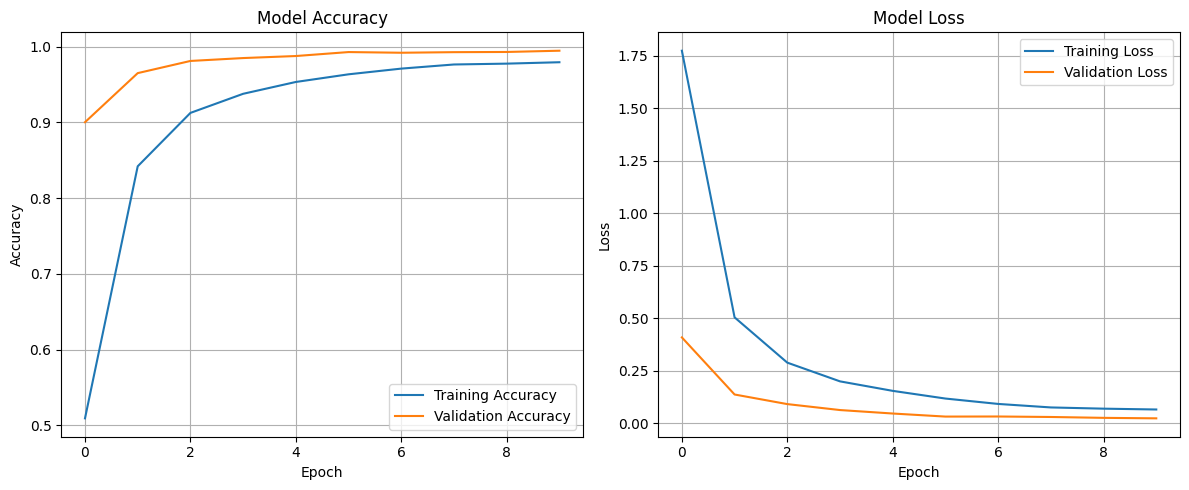

In [ ]:

import matplotlib.pyplot as plt

# Get training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Create two graphs
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# Save the trained model
model.save("/content/traffic_sign_recognition.keras")

print("Model saved successfully!")
print("File: traffic_sign_recognition.keras")


Model saved successfully!
File: traffic_sign_recognition.keras


In [ ]:

from google.colab import files

files.download("/content/traffic_sign_recognition.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

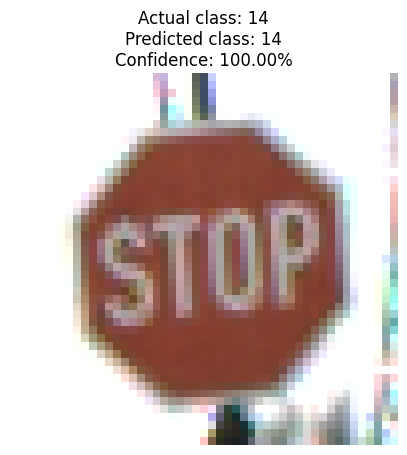

Actual class: 14
Predicted class: 14
Prediction confidence: 100.00%


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Select one image from the dataset
class_id = 14
class_path = f"/content/traffic_sign_dataset/Train/{class_id}"

image_files = [
    f for f in os.listdir(class_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

image_path = os.path.join(class_path, image_files[0])

# Prepare the image for prediction
image = Image.open(image_path).convert("RGB")
image_resized = image.resize((30, 30))

image_array = np.array(image_resized, dtype=np.float32) / 255.0
image_array = np.expand_dims(image_array, axis=0)

# Predict the traffic sign
prediction = model.predict(image_array, verbose=0)
predicted_class = int(np.argmax(prediction[0]))
confidence = float(np.max(prediction[0])) * 100

# Display the image and result
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Actual class: {class_id}\n"
    f"Predicted class: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual class:", class_id)
print("Predicted class:", predicted_class)
print(f"Prediction confidence: {confidence:.2f}%")


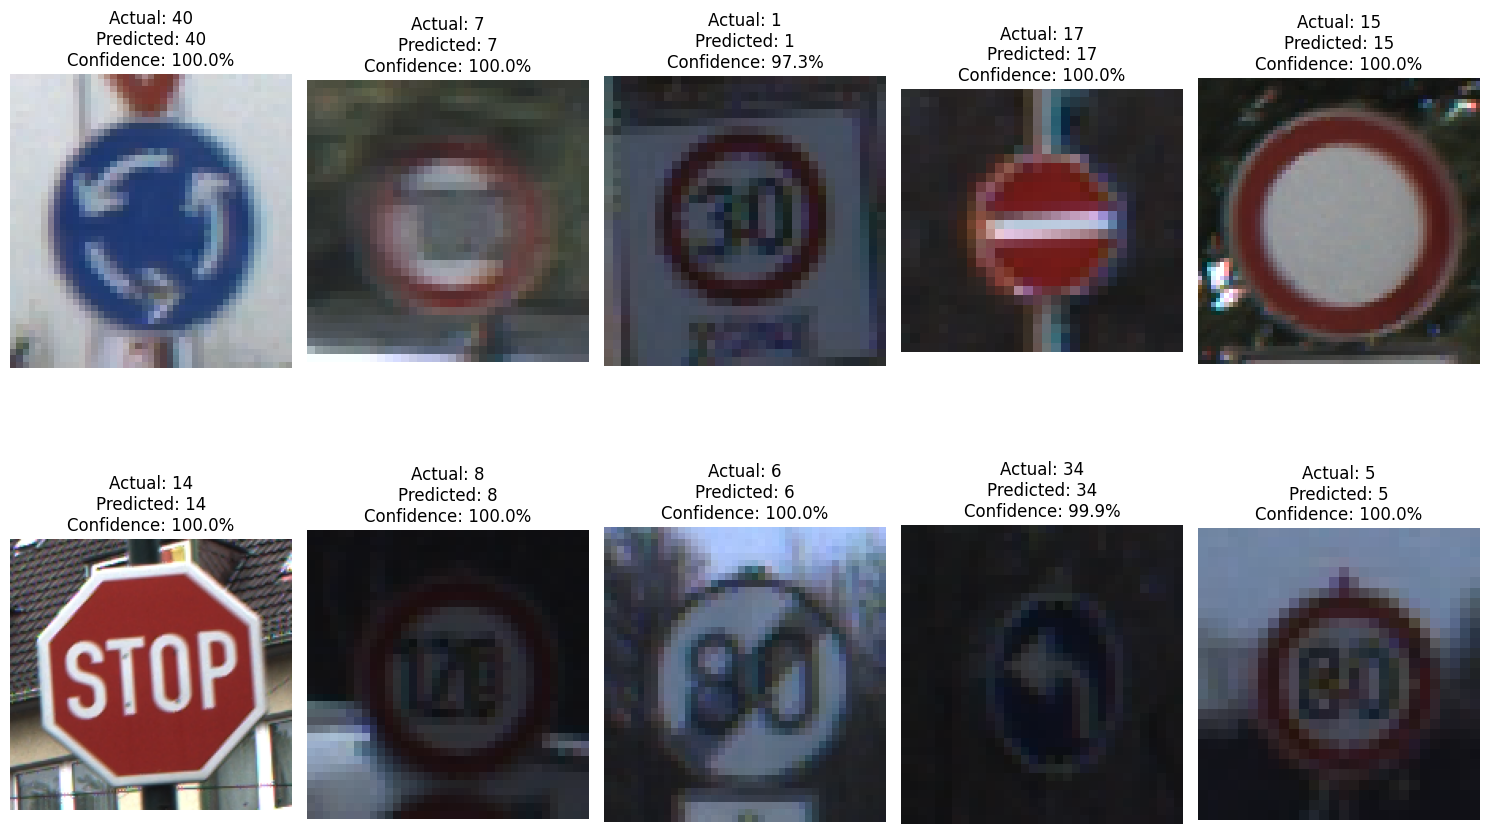

Correct predictions: 10/10
Accuracy on these 10 images: 100%


In [ ]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Choose 10 different traffic sign classes
random.seed(42)
test_classes = random.sample(range(43), 10)

correct = 0

plt.figure(figsize=(15, 10))

for i, class_id in enumerate(test_classes):
    class_path = f"/content/traffic_sign_dataset/Train/{class_id}"

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    image_path = os.path.join(class_path, random.choice(image_files))

    image = Image.open(image_path).convert("RGB")
    resized_image = image.resize((30, 30))

    image_array = np.array(resized_image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]
    predicted_class = int(np.argmax(prediction))
    confidence = float(np.max(prediction)) * 100

    if predicted_class == class_id:
        correct += 1

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Actual: {class_id}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.1f}%"
    )

plt.tight_layout()
plt.show()

print(f"Correct predictions: {correct}/10")
print(f"Accuracy on these 10 images: {correct * 10}%")


In [ ]:

import os

test_path = "/content/traffic_sign_dataset/Test"

print("Test folder exists:", os.path.exists(test_path))

if os.path.exists(test_path):
    test_files = [
        f for f in os.listdir(test_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print("Number of test images found:", len(test_files))
    print("Sample filenames:", test_files[:10])
else:
    print("Test folder not found. Please check the dataset folders.")


Test folder exists: True
Number of test images found: 12630
Sample filenames: ['12325.png', '05547.png', '09081.png', '00800.png', '04526.png', '05262.png', '09390.png', '03719.png', '06631.png', '03178.png']


In [ ]:

import pandas as pd
import os

csv_path = "/content/traffic_sign_dataset/Test.csv"

print("Test.csv exists:", os.path.exists(csv_path))

test_df = pd.read_csv(csv_path)

print("\nDataset columns:")
print(test_df.columns.tolist())

print("\nFirst 5 rows:")
display(test_df.head())

print("\nTotal rows in Test.csv:", len(test_df))


Test.csv exists: True

Dataset columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

First 5 rows:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png



Total rows in Test.csv: 12630


In [ ]:

import os
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report

# Load test labels
csv_path = "/content/traffic_sign_dataset/Test.csv"
test_df = pd.read_csv(csv_path)

test_path = "/content/traffic_sign_dataset"
IMG_SIZE = 30

X_test = []
y_test = []

print("Loading test images...")

for _, row in test_df.iterrows():
    image_path = os.path.join(test_path, row["Path"])

    image = Image.open(image_path).convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    X_test.append(np.array(image))
    y_test.append(int(row["ClassId"]))

X_test = np.array(X_test, dtype=np.float32) / 255.0
y_test = np.array(y_test, dtype=np.int64)

print("Test images loaded:", len(X_test))

# Predict in batches to limit memory use
probabilities = model.predict(X_test, batch_size=64, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print("\nFINAL TEST RESULTS")
print("------------------")
print("Total test images:", len(y_test))
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print("Correct predictions:", int(np.sum(y_pred == y_test)))
print("Incorrect predictions:", int(np.sum(y_pred != y_test)))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Loading test images...
Test images loaded: 12630
198/198 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step

FINAL TEST RESULTS
------------------
Total test images: 12630
Test accuracy: 95.41%
Correct predictions: 12050
Incorrect predictions: 580

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.83      0.91        60
           1       0.93      0.99      0.96       720
           2       0.94      0.97      0.96       750
           3       0.96      0.93      0.95       450
           4       0.96      0.98      0.97       660
           5       0.87      0.90      0.89       630
           6       1.00      0.80      0.89       150
           7       0.96      0.90      0.93       450
           8       0.97      0.93      0.95       450
           9       0.96      0.99      0.97       480
          10       0.99      0.99      0.99       660
          11       0.95      0.98      0.96       420
          12       0.98      0.99      0.9

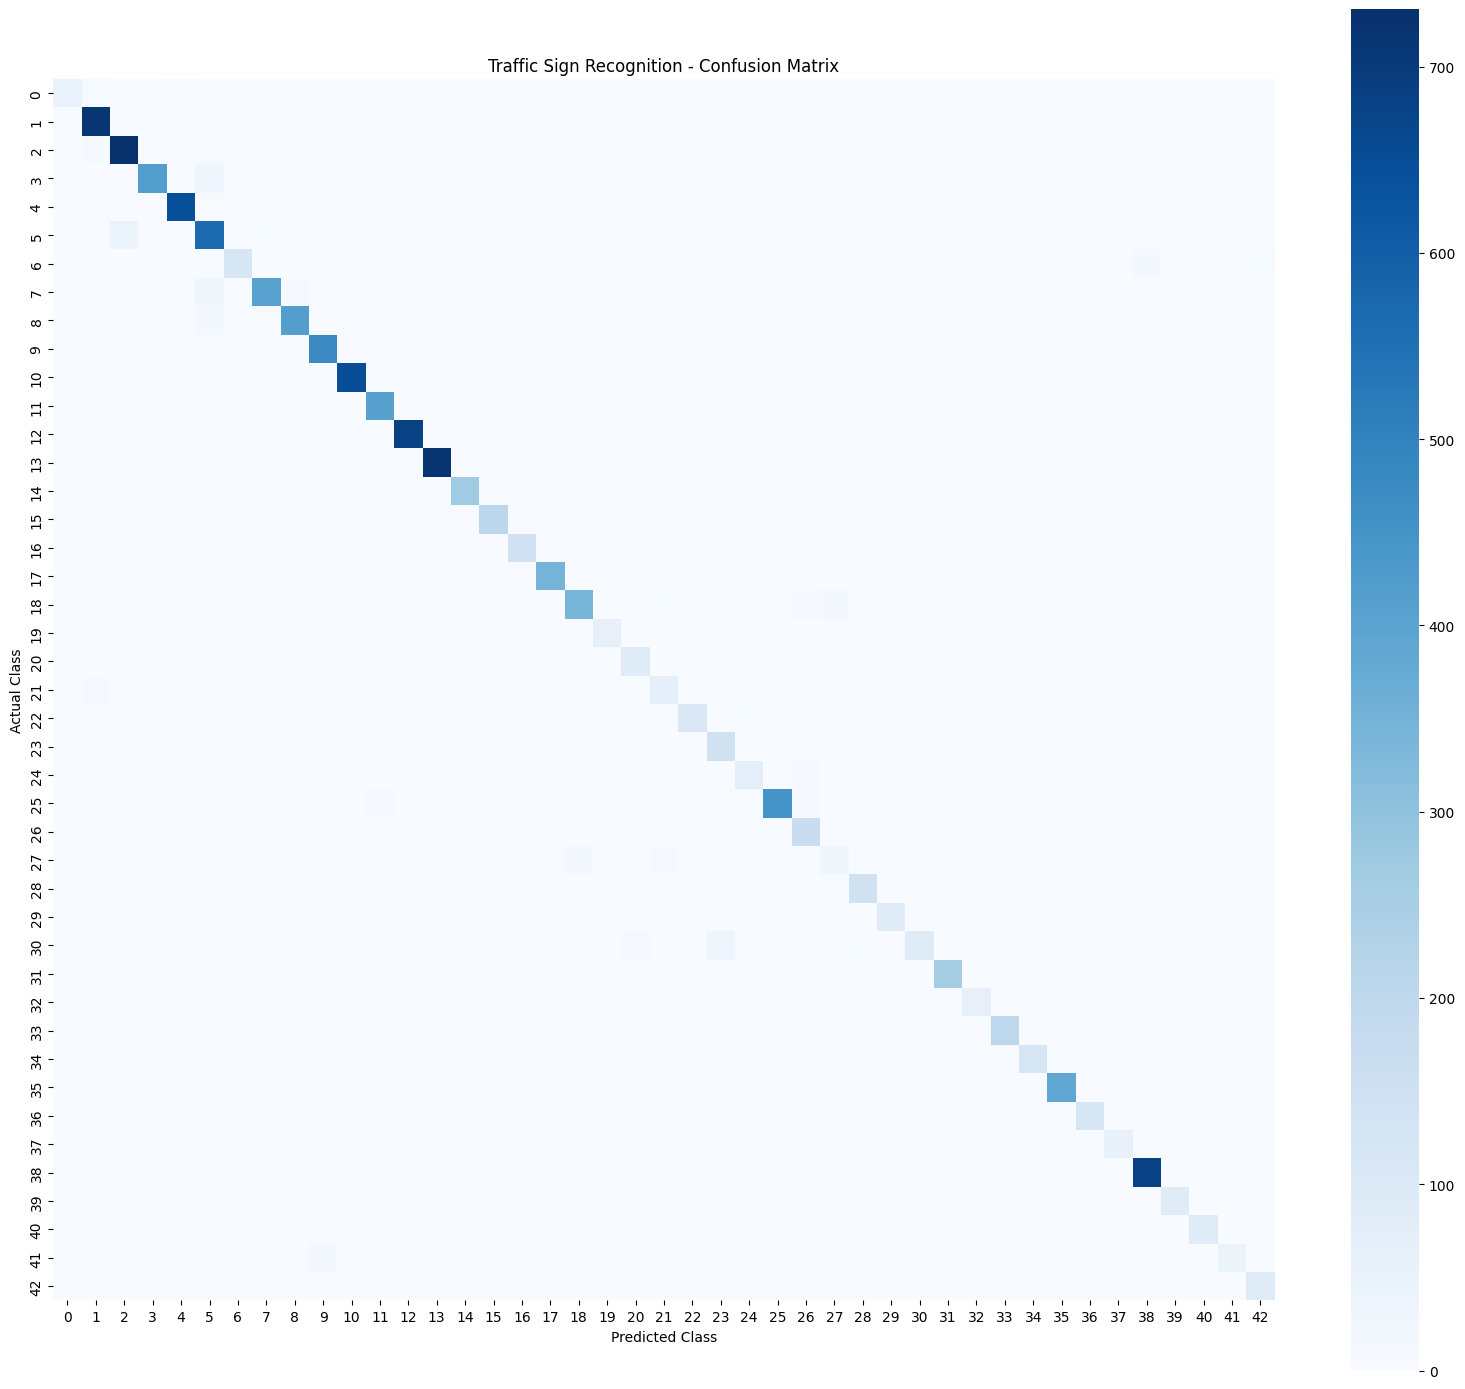

Confusion matrix created successfully!


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(16, 14))
sns.heatmap(
    cm,
    cmap="Blues",
    annot=False,
    fmt="d",
    square=True
)

plt.title("Traffic Sign Recognition - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("Confusion matrix created successfully!")


In [ ]:

import pandas as pd
import numpy as np

# Save actual and predicted labels
results_df = pd.DataFrame({
    "Image_Path": test_df["Path"],
    "Actual_Class": y_test,
    "Predicted_Class": y_pred,
    "Correct": y_test == y_pred,
    "Confidence_Percent": np.max(probabilities, axis=1) * 100
})

results_file = "/content/traffic_sign_test_results.csv"
results_df.to_csv(results_file, index=False)

print("Test results saved successfully!")
print("File:", results_file)
print("Total records:", len(results_df))
print("\nFirst 10 results:")
display(results_df.head(10))


Test results saved successfully!
File: /content/traffic_sign_test_results.csv
Total records: 12630

First 10 results:


,Image_Path,Actual_Class,Predicted_Class,Correct,Confidence_Percent
0,Test/00000.png,16,16,True,99.999992
1,Test/00001.png,1,1,True,99.998695
2,Test/00002.png,38,38,True,99.999992
3,Test/00003.png,33,33,True,99.999992
4,Test/00004.png,11,11,True,99.999992
5,Test/00005.png,38,38,True,99.999992
6,Test/00006.png,18,18,True,99.999992
7,Test/00007.png,12,12,True,99.999985
8,Test/00008.png,25,25,True,99.999992
9,Test/00009.png,35,35,True,99.999992


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# Verify the saved test results
results_df = pd.read_csv("/content/traffic_sign_test_results.csv")

actual = results_df["Actual_Class"]
predicted = results_df["Predicted_Class"]

total = len(results_df)
correct = int((actual == predicted).sum())
incorrect = total - correct
accuracy = accuracy_score(actual, predicted) * 100
average_confidence = results_df["Confidence_Percent"].mean()

print("===== FINAL PROJECT RESULTS =====")
print(f"Total test images       : {total}")
print(f"Correct predictions     : {correct}")
print(f"Incorrect predictions   : {incorrect}")
print(f"Recalculated accuracy   : {accuracy:.2f}%")
print(f"Average confidence score: {average_confidence:.2f}%")

print("\n===== VERIFICATION =====")
print("All rows have valid class labels:",
      results_df["Actual_Class"].between(0, 42).all()
      and results_df["Predicted_Class"].between(0, 42).all())

print("Correct column matches predictions:",
      (results_df["Correct"] ==
       (results_df["Actual_Class"] ==
        results_df["Predicted_Class"])).all())

print("Total count is correct:", total == 12630)


===== FINAL PROJECT RESULTS =====
Total test images       : 12630
Correct predictions     : 12050
Incorrect predictions   : 580
Recalculated accuracy   : 95.41%
Average confidence score: 97.43%

===== VERIFICATION =====
All rows have valid class labels: True
Correct column matches predictions: True
Total count is correct: True


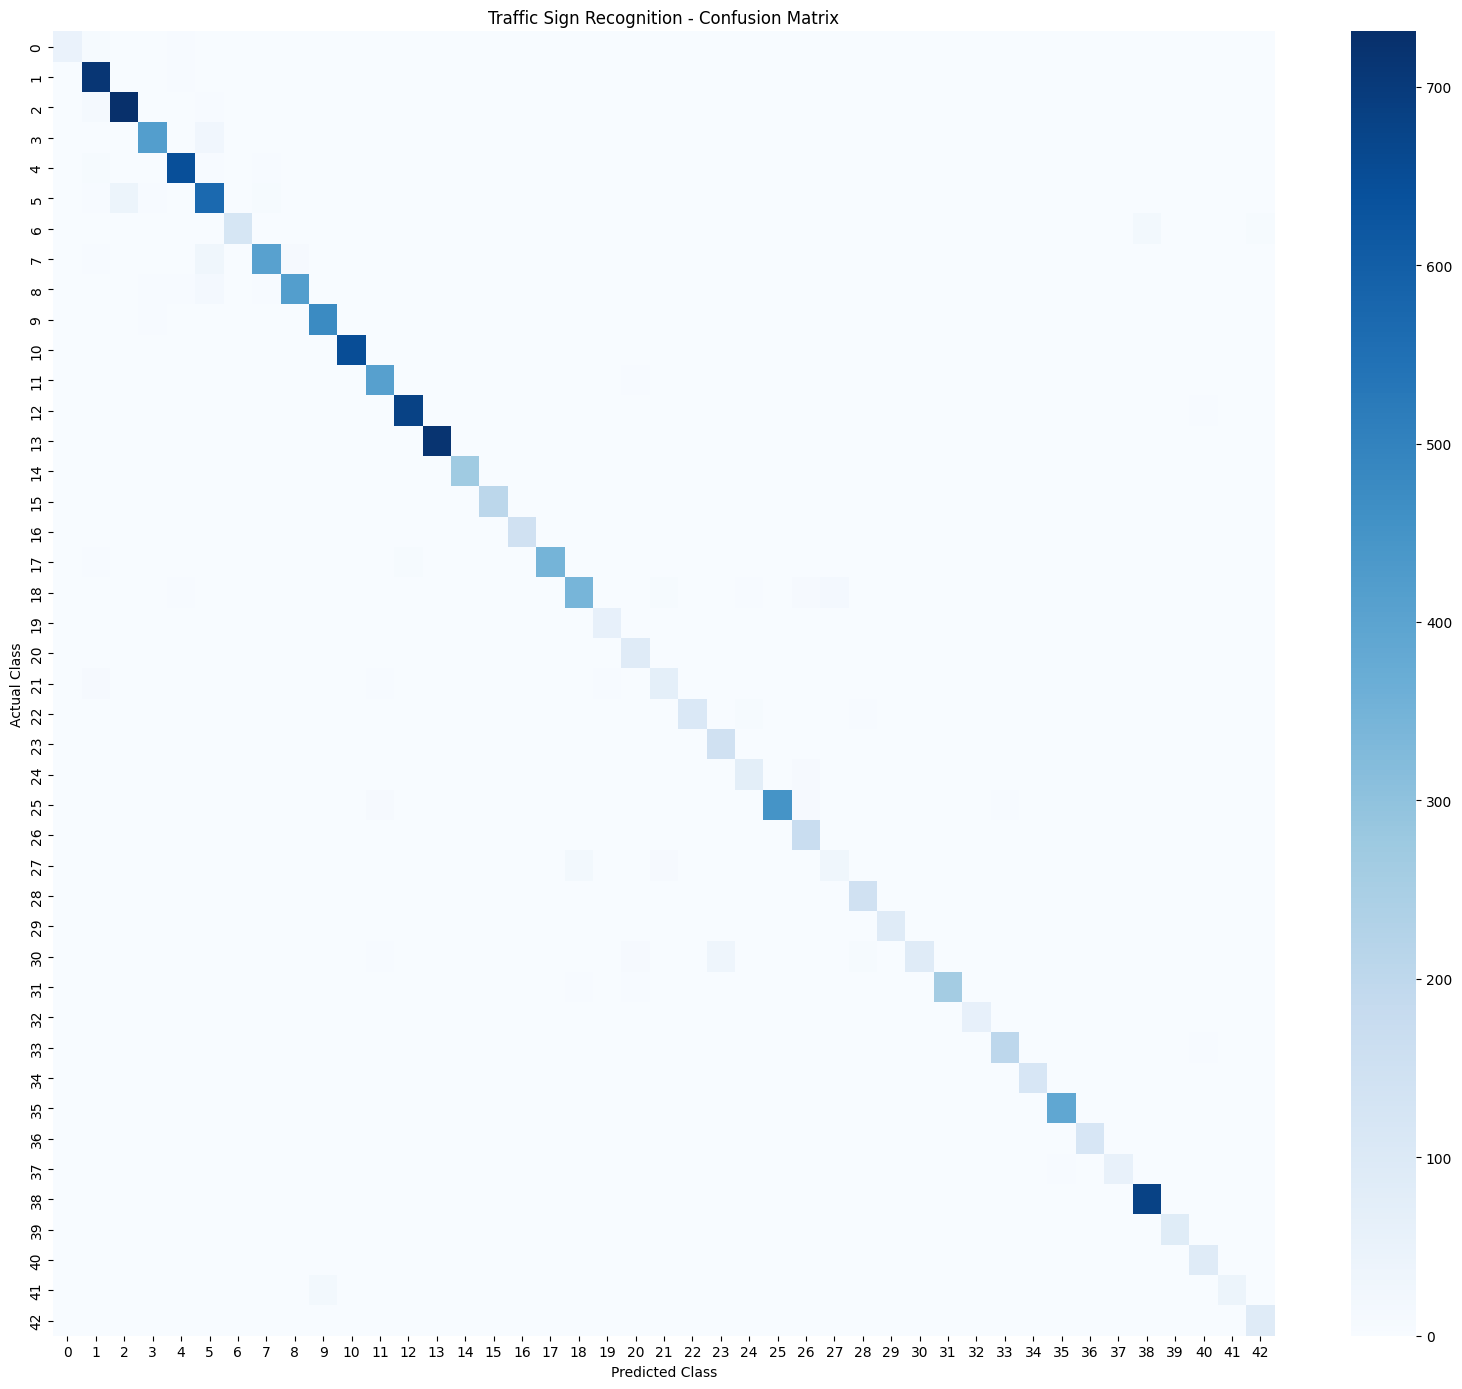

Confusion matrix saved successfully!
File: traffic_sign_confusion_matrix.png


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create and display the graph
plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap="Blues", annot=False, fmt="d")
plt.title("Traffic Sign Recognition - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

# Save graph as an image
plt.savefig(
    "/content/traffic_sign_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Confusion matrix saved successfully!")
print("File: traffic_sign_confusion_matrix.png")


In [ ]:

from google.colab import files

files.download("/content/traffic_sign_confusion_matrix.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

readme_content = """
# Traffic Sign Recognition Using CNN

## Project Overview
This project uses a Convolutional Neural Network (CNN) to classify
traffic signs into 43 different classes using the GTSRB dataset.

## Objectives
- Load and preprocess traffic sign images.
- Build and train a CNN model.
- Evaluate performance on separate test images.
- Generate predictions and a confusion matrix.

## Technologies Used
- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Dataset
German Traffic Sign Recognition Benchmark (GTSRB).

- Traffic sign classes: 43
- Training images loaded: 39,209
- Independent test images: 12,630

## Model
The CNN contains convolutional layers, max-pooling layers,
a fully connected layer, dropout, and a 43-class softmax output.

## Results
- Validation accuracy: 99.46%
- Independent test accuracy: 95.41%
- Correct test predictions: 12,050
- Incorrect test predictions: 580
- Total test images: 12,630

## Output Files
- `traffic_sign_recognition.keras` - trained model
- `traffic_sign_test_results.csv` - test predictions
- `traffic_sign_confusion_matrix.png` - confusion matrix graph

## How It Works
1. Traffic sign images are resized to 30 x 30 pixels.
2. Pixel values are normalized between 0 and 1.
3. The CNN learns image features during training.
4. The trained model predicts one of 43 traffic sign classes.
5. Performance is evaluated using separate test images.

## Limitations
Performance may vary with image quality, lighting, viewing angle,
and traffic signs that are visually similar.

## Conclusion
The CNN achieved 95.41% accuracy on 12,630 independent test images.
This demonstrates the potential of deep learning for traffic sign
classification.

## Author
Ben Christos Thomas
"""

with open("/content/README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README file created successfully!")
print("File: /content/README.md")
print("\nPreview:")
print(readme_content[:1000])


README file created successfully!
File: /content/README.md

Preview:

# Traffic Sign Recognition Using CNN

## Project Overview
This project uses a Convolutional Neural Network (CNN) to classify
traffic signs into 43 different classes using the GTSRB dataset.

## Objectives
- Load and preprocess traffic sign images.
- Build and train a CNN model.
- Evaluate performance on separate test images.
- Generate predictions and a confusion matrix.

## Technologies Used
- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Dataset
German Traffic Sign Recognition Benchmark (GTSRB).

- Traffic sign classes: 43
- Training images loaded: 39,209
- Independent test images: 12,630

## Model
The CNN contains convolutional layers, max-pooling layers,
a fully connected layer, dropout, and a 43-class softmax output.

## Results
- Validation accuracy: 99.46%
- Independent test accuracy: 95.41%
- Correct test predictions: 12,050
- Incorrect test predictions:

In [ ]:

import os
import zipfile

project_dir = "/content/Traffic_Sign_Recognition"
os.makedirs(project_dir, exist_ok=True)

# Files to include in the project
files_to_copy = [
    "/content/traffic_sign_recognition.keras",
    "/content/traffic_sign_test_results.csv",
    "/content/traffic_sign_confusion_matrix.png",
    "/content/README.md"
]

# Copy files into the project folder
import shutil

for file_path in files_to_copy:
    if os.path.exists(file_path):
        shutil.copy2(file_path, project_dir)
        print("Added:", os.path.basename(file_path))
    else:
        print("WARNING - File not found:", file_path)

# Create a ZIP archive
zip_path = "/content/Traffic_Sign_Recognition.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in os.listdir(project_dir):
        full_path = os.path.join(project_dir, filename)
        if os.path.isfile(full_path):
            zipf.write(full_path, arcname=filename)

print("\nProject folder:", project_dir)
print("ZIP file created:", zip_path)
print("Files in project folder:", os.listdir(project_dir))


Added: traffic_sign_recognition.keras
Added: traffic_sign_test_results.csv
Added: traffic_sign_confusion_matrix.png
Added: README.md

Project folder: /content/Traffic_Sign_Recognition
ZIP file created: /content/Traffic_Sign_Recognition.zip
Files in project folder: ['traffic_sign_confusion_matrix.png', 'traffic_sign_recognition.keras', 'README.md', 'traffic_sign_test_results.csv']


In [ ]:

from google.colab import files

files.download("/content/Traffic_Sign_Recognition.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>